# Especialização em Ciência de Dados - Turma 2018.1 - Facens
## Projeto em Ciência de Dados Trabalho 1 – Análise Exploratória 


|**Professor:**|Fernando Vieira da Silva, M.Sc.|
|-----|-----------------------------------|

|**Nome:**|José Diniz Junior            |**RA:**|183134|
|-----|-----------------------------|---|------|
|**Nome:**|Roberto Leonardo Rodrigues   |**RA:**|060235|

O objetivo deste trabalho é explorar e entender melhor as características dos dados que serão utilizados durante o Trabalho de Conclusão do Curso. Use os conhecimentos adquiridos nas disciplinas de Visualização de Dados, Estatística e Programação em Python para Ciência de Dados. Dica: aproveite essa oportunidade para tirar suas próprias dúvidas sobre os dados e conhecer melhor o problema que você escolheu estudar. Este trabalho deve ser entregue em forma de um notebook Jupyter.

1 – Observe os dados inconsistentes. Quais campos possuem registros faltantes? (Zero, vazio, negativo, NaN, etc). Quais possuem valores fora da faixa esperada? (ex: em um dataset com dados de pessoas, há registros de altura maior que 2,5m?). Qual a proporção em relação aos dados corretos? Para cada uma das campos com dados faltantes, qual sua proposta para tratar os dados? (ex: pretende preencher de alguma forma? Se sim, como?) (3 pontos)

In [98]:
import pandas as pd
import plotly.graph_objs as go
from plotly.offline import init_notebook_mode, iplot
init_notebook_mode(connected=True)
import numpy as np

import matplotlib.pyplot as plt
import matplotlib
%matplotlib inline
matplotlib.rcParams['font.size'] = 12
matplotlib.rcParams['figure.dpi'] = 150

import seaborn as sns
from IPython.core.pylabtools import figsize
from matplotlib.ticker import FormatStrFormatter

import plotly.plotly as py
import plotly.offline as py

In [33]:
dfFT = pd.read_csv('Fotovoltaico.csv', encoding='utf-8', quotechar='"')
dfFT.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 684450 entries, 0 to 684449
Data columns (total 9 columns):
data             684450 non-null object
painel           670431 non-null float64
energia_dia      669954 non-null float64
energia_ano      669954 non-null float64
energia_total    669954 non-null float64
potencia         669954 non-null float64
power_led        684450 non-null int64
solarnet_led     684450 non-null int64
solarweb_led     684450 non-null int64
dtypes: float64(5), int64(3), object(1)
memory usage: 47.0+ MB


In [34]:
dfFT.head()

,data,painel,energia_dia,energia_ano,energia_total,potencia,power_led,solarnet_led,solarweb_led
0,2018-09-30 23:58:56.970,2.0,31640.0,14760184.0,48471100.0,0.0,1,1,1
1,2018-09-30 23:58:53.120,4.0,30504.0,11202444.0,37946500.0,0.0,1,1,1
2,2018-09-30 23:58:49.283,1.0,42950.0,19280784.0,63919004.0,0.0,1,1,1
3,2018-09-30 23:58:40.173,3.0,43730.0,15342723.0,51709800.0,0.0,1,1,1
4,2018-09-30 23:58:36.377,2.0,31640.0,14760184.0,48471100.0,0.0,1,1,1


In [35]:
# Verificando dados faltantes por coluna
dfFT.isna().sum()

data                 0
painel           14019
energia_dia      14496
energia_ano      14496
energia_total    14496
potencia         14496
power_led            0
solarnet_led         0
solarweb_led         0
dtype: int64

Observado que cinco colunas (painel, energia_dia, energia_ano, energia_total, potencia) possuiam dados faltantes por falta de medição(inxistência de valores ou somente informação com o valor do dado da coluna painel), com isso optou-se por remover essas linhas com registros faltantes, alguns casos até foi registrado qual foi o painel mas sem registro de outras informações, sendo assim, dados irrelevantes.

In [36]:
#Removendo registros com dados faltantes
dfFT.dropna(inplace=True)
#Verificando novamente se há dados faltantes
dfFT.isna().sum()

data             0
painel           0
energia_dia      0
energia_ano      0
energia_total    0
potencia         0
power_led        0
solarnet_led     0
solarweb_led     0
dtype: int64

In [37]:
dfFT.isin({0}).sum()

data                  0
painel                0
energia_dia      174617
energia_ano           0
energia_total         0
potencia         350949
power_led           302
solarnet_led        302
solarweb_led        302
dtype: int64

Valores com zero são aceitváveis pois em determinados períodos do dia não ocorrem radiação solar sobre os paineis.

In [38]:
#Verificando  se existem campos com valores negativos 
print((dfFT < 0).sum().drop('data'))

painel           0
energia_dia      0
energia_ano      0
energia_total    0
potencia         0
power_led        0
solarnet_led     0
solarweb_led     0
dtype: int64


In [39]:

Perguntar o que é as colunas power_led, leds

SyntaxError: invalid syntax (<ipython-input-39-f3d9bb56efd7>, line 2)

In [55]:
#gerando mais campos a partir do campo data
dfFT['hora'] = pd.to_datetime(dfFT['data']).dt.hour
dfFT['dia'] = pd.to_datetime(dfFT['data']).dt.day

In [56]:
dfFT.head()

,data,painel,energia_dia,energia_ano,energia_total,potencia,power_led,solarnet_led,solarweb_led,hora,dia
0,2018-09-30 23:58:56.970,2.0,31640.0,14760184.0,48471100.0,0.0,1,1,1,23,30
1,2018-09-30 23:58:53.120,4.0,30504.0,11202444.0,37946500.0,0.0,1,1,1,23,30
2,2018-09-30 23:58:49.283,1.0,42950.0,19280784.0,63919004.0,0.0,1,1,1,23,30
3,2018-09-30 23:58:40.173,3.0,43730.0,15342723.0,51709800.0,0.0,1,1,1,23,30
4,2018-09-30 23:58:36.377,2.0,31640.0,14760184.0,48471100.0,0.0,1,1,1,23,30


In [ ]:
#Verificando se faixa de valores das colunas
dfFT.describe()

In [ ]:
dfMT = pd.read_csv('Meteorologia.csv', encoding='utf-8')
dfMT.info()

In [ ]:
# Verificando dados faltantes por coluna
dfMT.isna().sum()

In [40]:
# Dados dados com valor zero por coluna
dfMT.isin({0}).sum()

data                          0
deficit_vapor_vmin            0
deficit_vapor_vmedio          0
ponto_orvalho_vmin            0
ponto_orvalho_vmedio          0
precipitacao_valor         4147
radiacao_solar_valor       2405
temperatura_ar_vmin           0
temperatura_ar_vmedio         0
temperatura_ar_vmax           0
umidade_ar_vmin               0
umidade_ar_vmedio             0
umidade_ar_vmax               0
velocidade_vento_vmedio    1610
velocidade_vento_vmax      1409
hora                        159
dia                           0
dtype: int64

Identificado que existem colunas com valores zero, porém, é foi considerado aceitável visto que são medidas momentáneas podendo ser variáveis ao decorrer de um dia.

In [140]:
#Verificando se faixa de valores das colunas
dfFT.describe()

,painel,energia_dia,energia_ano,energia_total,potencia,power_led,solarnet_led,solarweb_led,hora,dia
count,669954.000000,669954.000000,6.699540e+05,6.699540e+05,669954.000000,669954.000000,669954.000000,669954.000000,669954.000000,669954.000000
mean,2.499973,24054.271769,1.434321e+07,4.970747e+07,2300.205275,0.999549,0.999549,0.999549,11.411619,15.610870
std,1.118334,24335.027877,2.760229e+06,9.130962e+06,3652.541291,0.021227,0.021227,0.021227,6.958309,8.639507
min,1.000000,0.000000,9.974486e+06,3.671850e+07,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,1.000000,0.000000,1.120244e+07,3.794650e+07,0.000000,1.000000,1.000000,1.000000,5.000000,8.000000
50%,2.000000,16735.000000,1.425701e+07,4.847110e+07,0.000000,1.000000,1.000000,1.000000,11.000000,16.000000
75%,4.000000,45940.000000,1.719769e+07,6.183590e+07,3647.000000,1.000000,1.000000,1.000000,17.000000,23.000000
max,4.000000,79350.000000,1.928078e+07,6.391900e+07,20256.000000,1.000000,1.000000,1.000000,23.000000,30.000000


In [42]:
#Verificando  se existem campos com valores negativos 
print((dfMT < 0).sum().drop('data'))

deficit_vapor_vmin         0
deficit_vapor_vmedio       0
ponto_orvalho_vmin         0
ponto_orvalho_vmedio       0
precipitacao_valor         0
radiacao_solar_valor       0
temperatura_ar_vmin        0
temperatura_ar_vmedio      0
temperatura_ar_vmax        0
umidade_ar_vmin            0
umidade_ar_vmedio          0
umidade_ar_vmax            0
velocidade_vento_vmedio    0
velocidade_vento_vmax      0
hora                       0
dia                        0
dtype: int64


In [43]:
dfMT.head()

,data,deficit_vapor_vmin,deficit_vapor_vmedio,ponto_orvalho_vmin,ponto_orvalho_vmedio,precipitacao_valor,radiacao_solar_valor,temperatura_ar_vmin,temperatura_ar_vmedio,temperatura_ar_vmax,umidade_ar_vmin,umidade_ar_vmedio,umidade_ar_vmax,velocidade_vento_vmedio,velocidade_vento_vmax,hora,dia
0,2018-09-30 23:50:06.000,0.25,0.25,18.9,18.9,0.0,0.0,20.79,20.80,20.82,89.38,89.56,89.74,0.0,0.0,23,30
1,2018-09-30 23:40:07.000,0.26,0.26,19.0,19.0,0.0,0.0,20.87,20.93,21.00,88.80,88.94,89.08,0.2,0.5,23,30
2,2018-09-30 23:30:06.000,0.27,0.27,19.0,19.0,0.0,0.0,20.98,21.00,21.02,88.95,88.99,89.03,0.0,0.1,23,30
3,2018-09-30 23:20:07.000,0.27,0.27,19.1,19.1,0.0,0.0,21.06,21.06,21.07,88.88,89.00,89.13,0.0,0.1,23,30
4,2018-09-30 23:10:06.000,0.25,0.25,19.1,19.1,0.0,0.0,20.91,20.94,20.97,89.47,89.66,89.85,0.0,0.0,23,30


In [58]:
#gerando mais campos a partir do campo data
dfMT['hora'] = pd.to_datetime(dfMT['data']).dt.hour
dfMT['dia'] = pd.to_datetime(dfMT['data']).dt.day

In [59]:
dfMT.head()

,data,deficit_vapor_vmin,deficit_vapor_vmedio,ponto_orvalho_vmin,ponto_orvalho_vmedio,precipitacao_valor,radiacao_solar_valor,temperatura_ar_vmin,temperatura_ar_vmedio,temperatura_ar_vmax,umidade_ar_vmin,umidade_ar_vmedio,umidade_ar_vmax,velocidade_vento_vmedio,velocidade_vento_vmax,hora,dia
0,2018-09-30 23:50:06.000,0.25,0.25,18.9,18.9,0.0,0.0,20.79,20.80,20.82,89.38,89.56,89.74,0.0,0.0,23,30
1,2018-09-30 23:40:07.000,0.26,0.26,19.0,19.0,0.0,0.0,20.87,20.93,21.00,88.80,88.94,89.08,0.2,0.5,23,30
2,2018-09-30 23:30:06.000,0.27,0.27,19.0,19.0,0.0,0.0,20.98,21.00,21.02,88.95,88.99,89.03,0.0,0.1,23,30
3,2018-09-30 23:20:07.000,0.27,0.27,19.1,19.1,0.0,0.0,21.06,21.06,21.07,88.88,89.00,89.13,0.0,0.1,23,30
4,2018-09-30 23:10:06.000,0.25,0.25,19.1,19.1,0.0,0.0,20.91,20.94,20.97,89.47,89.66,89.85,0.0,0.0,23,30


In [52]:
temp = pd.DataFrame(dfMT.groupby('dia').temperatura_ar_vmedio.mean()).reset_index()

In [60]:
trace1 = go.Scatter(
                    x = temp['dia'],
                    y = temp['temperatura_ar_vmedio'],
                    mode = 'lines+markers')


data = [trace1]
layout = dict(title = 'Temperatura por dia',
              xaxis= dict(title= 'Dia',zeroline= False,
                         ticks='outside'),
              yaxis = dict(title= 'Temperatura °C',
                            ticks='outside'
                          )
             )
fig = dict(data = data, layout = layout)
iplot(fig)

In [98]:
tomar cuidado com o campo energi_dia , pois tem delay, pegar valor de ultimo valor de 23:59:xx hs

SyntaxError: invalid syntax (<ipython-input-98-30b5a858c5d7>, line 1)

2 – Liste as principais dúvidas sobre os dados (pelo menos 5). Seja específico e faça perguntas que possam te ajudar a escolher quais campos serão úteis e podem te ajudar a ter ideias de como montar sua solução no futuro. Também faça perguntas que te ajudem a identificar campos irrelevantes e que devem ser descartadas no futuro. Questões simples como “Qual a média/variância/desvio padrão do campo X?” não serão aceitas, mas perceba que pode ser interessante realizar esses cálculos para ter respostas de questões mais elaboradas. Você também pode elaborar uma questão como essa, desde faça esses cálculos para todos os campos, por exemplo: “Qual é a média, variância e desvio padrão de cada campo numérico do dataset?”  (2 pontos). 

In [99]:
campos descartados
5 perguntas

SyntaxError: invalid syntax (<ipython-input-99-6ecee11bad9b>, line 1)

1 - Qual a relação entre a radição solar com a geração de potência?

2 - Qual a energia gerada por painel fotovoltáico por dia?

3 - É possível determinar qual o período do dia a geração de energia é mais eficiente?

4 - O que a umidade do ar pode interferir na geração de energia?

5 - Qual a temperatura ideal para alcançar a potência máxima do painel?

3 – Plote gráficos para responder às questões levantadas acima. Escolha os gráficos mais adequados para cada questão. Seja convincente e didático: pense que o observador pode não entender sobre o problema, como convencê-lo das suas afirmações? Capriche na apresentação! Faça uso de cores, legendas e outros recursos que deixem os gráficos visualmente agradáveis. (3 pontos)


In [61]:
trace1 = pd.DataFrame(dfMT.groupby('dia').radiacao_solar_valor.mean()).reset_index()
trace2 = pd.DataFrame(dfFT.groupby('dia').potencia.mean()).reset_index()
trace2

,dia,potencia
0,1,2729.755558
1,2,2301.687470
2,3,985.053069
3,4,1443.129553
4,5,589.118899
5,6,3256.159859
6,7,3107.374029
7,8,3092.691065
8,9,3153.663840
9,10,3034.656937


In [62]:
result = pd.merge(trace1,trace2,how='inner',on='dia')
result

,dia,radiacao_solar_valor,potencia
0,1,190.762238,2729.755558
1,2,159.496503,2301.687470
2,3,62.335664,985.053069
3,4,62.902098,1443.129553
4,5,140.517483,589.118899
5,6,221.361111,3256.159859
6,7,220.174825,3107.374029
7,8,219.594406,3092.691065
8,9,218.573427,3153.663840
9,10,208.839161,3034.656937


In [63]:
coordenadaOcr = pd.DataFrame(result)
coordenadaOcr

,dia,radiacao_solar_valor,potencia
0,1,190.762238,2729.755558
1,2,159.496503,2301.687470
2,3,62.335664,985.053069
3,4,62.902098,1443.129553
4,5,140.517483,589.118899
5,6,221.361111,3256.159859
6,7,220.174825,3107.374029
7,8,219.594406,3092.691065
8,9,218.573427,3153.663840
9,10,208.839161,3034.656937


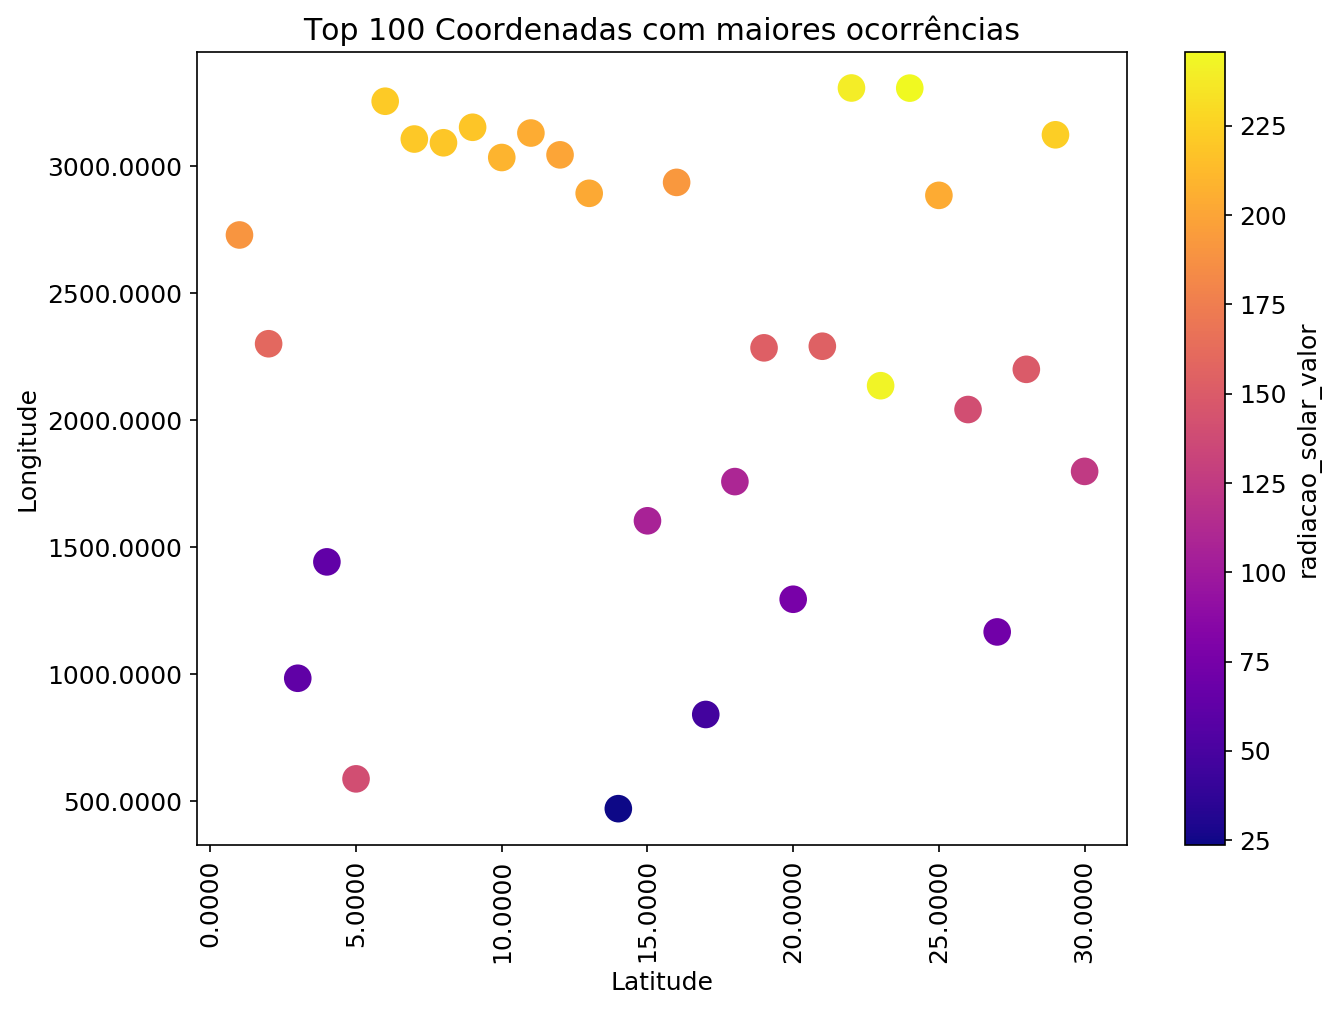

In [64]:
figsize(10,7);
fig, ax = plt.subplots(); 
ax.yaxis.set_major_formatter(FormatStrFormatter('%.4f'));
ax.xaxis.set_major_formatter(FormatStrFormatter('%.4f'));
coordenadaOcr.plot(kind="scatter", x='dia', y='potencia', 
                   c='radiacao_solar_valor', s=150, cmap="plasma", ax=ax,rot=90);
plt.xlabel('Latitude');
plt.ylabel('Longitude');
plt.title('Top 100 Coordenadas com maiores ocorrências');
plt.show()

In [65]:
#1 - Qual a relação entre a radição solar com a geração de potência?
trace1 = pd.DataFrame(dfMT.groupby('dia').radiacao_solar_valor.mean()).reset_index()
trace2 = pd.DataFrame(dfFT.groupby('dia').potencia.mean()).reset_index()


trace1 = go.Scatter(
                    x = trace1['dia'],
                    y = trace1['radiacao_solar_valor'],
                    mode = 'lines+markers')
trace2 = go.Scatter(
                    x = trace2['dia'],
                    y = trace2['potencia'],
                    mode = 'lines+markers')


data = [trace1,trace2]
layout = dict(title = 'Temperatura por dia',
              xaxis= dict(title= 'Dia',zeroline= False,
                         ticks='outside'),
              yaxis = dict(title= 'Temperatura °C',
                            ticks='outside'
                          )
             )
fig = dict(data = data, layout = layout)
iplot(fig)

In [66]:
#2 - Qual a energia gerada por painel fotovoltáico por dia?
teste = dfFT.groupby(['painel','dia']).energia_dia.first()
teste

painel  dia
1.0     1      65150.0
        2      56930.0
        3      21571.0
        4      25671.0
        5      54820.0
        6      65530.0
        7      65530.0
        8      65530.0
        9      65530.0
        10     65530.0
        11     65530.0
        12     65530.0
        13     65530.0
        14      8044.0
        15     40450.0
        16     65540.0
        17     18530.0
        18     43300.0
        19     56160.0
        20     27156.0
        21     50150.0
        22     65540.0
        23     44070.0
        24     65540.0
        25     65530.0
        26     50460.0
        27     24247.0
        28     55290.0
        29     65530.0
        30     42950.0
                ...   
4.0     1      50800.0
        2      38330.0
        3      16263.0
        4      18023.0
        5      39920.0
        6      60020.0
        7      57740.0
        8      57340.0
        9      58010.0
        10     52650.0
        11     55040.0
        12     54560.0

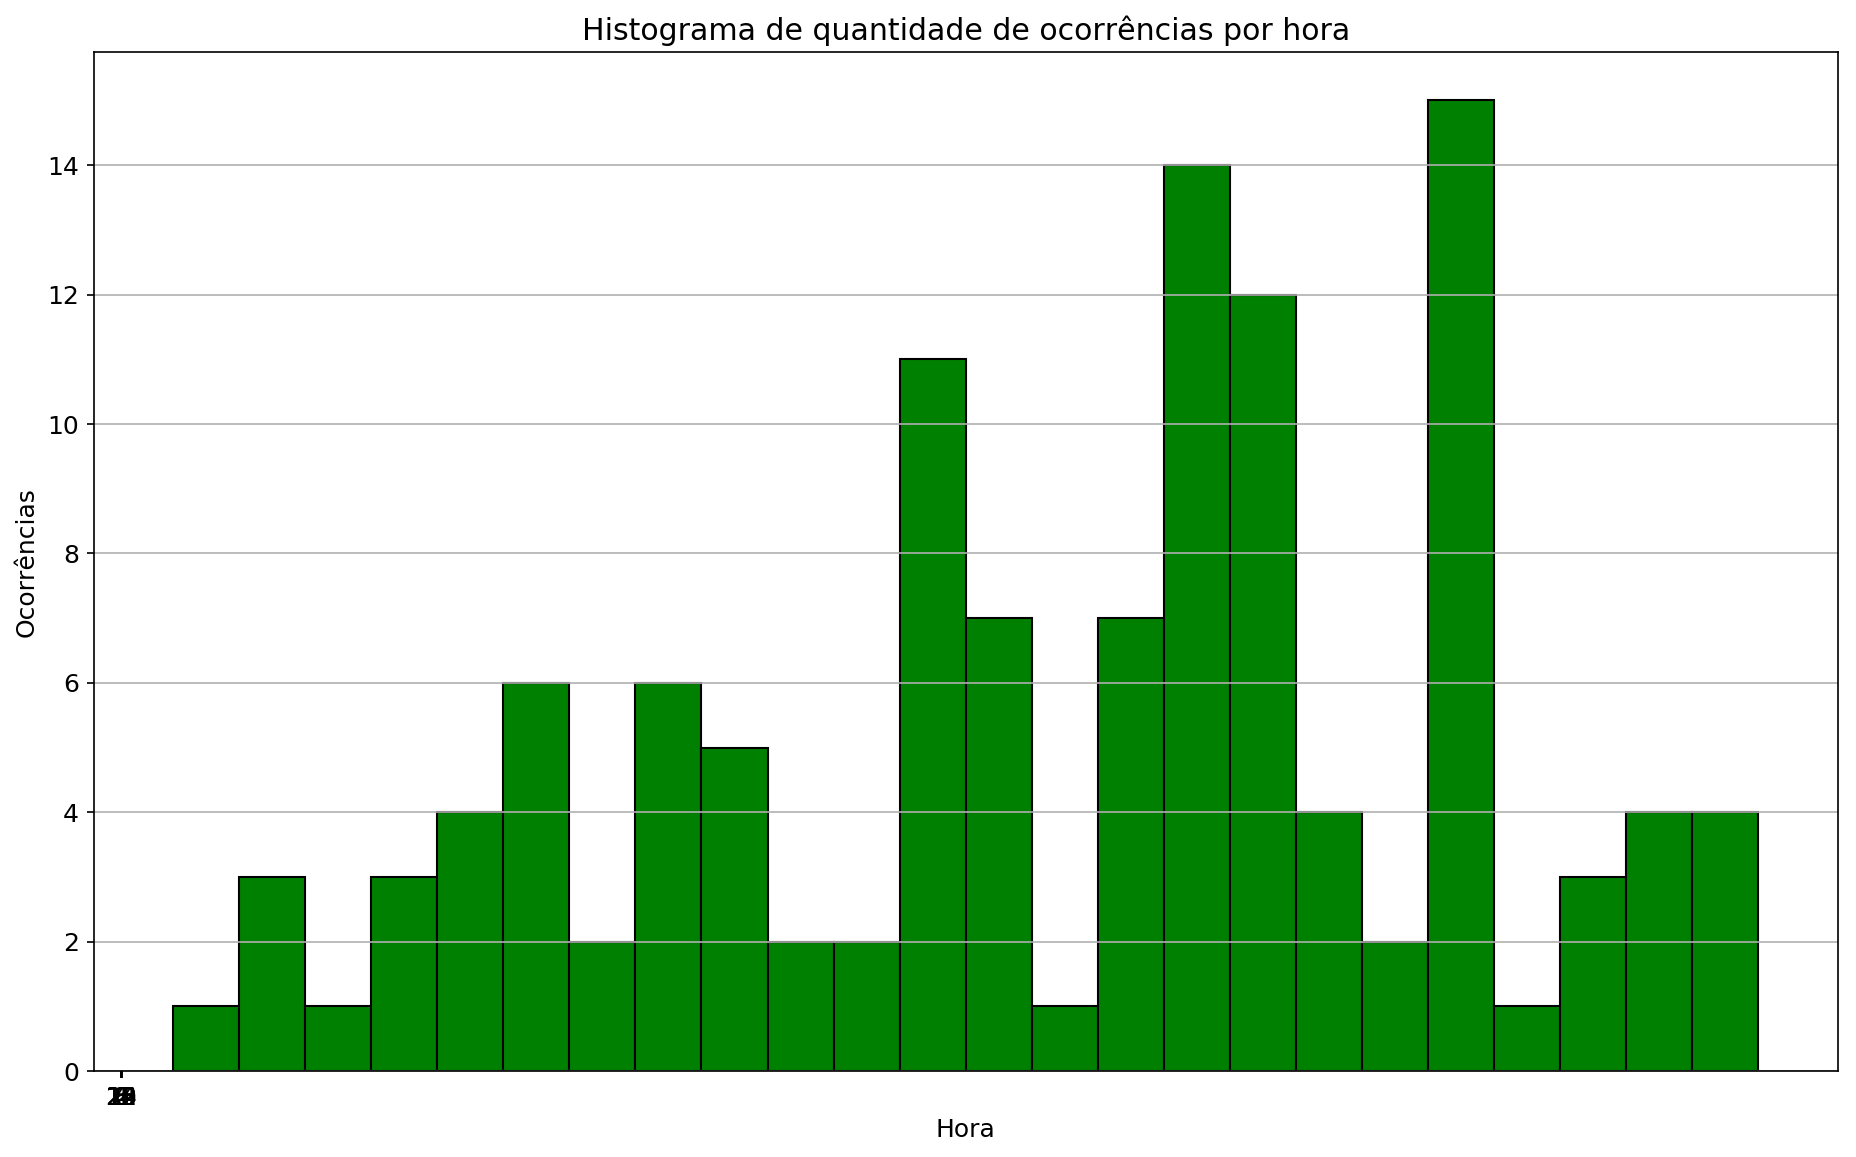

In [67]:
figsize(15,9)
plt.hist(teste, color = 'green', edgecolor = 'black',
         bins = int(195/8))

plt.title('Histograma de quantidade de ocorrências por hora')
plt.xlabel('Hora'); 
plt.ylabel('Ocorrências');
plt.xticks(np.arange(0, 24, step=2))
plt.grid(axis='y')

3 - É possível determinar qual o período do dia a geração de energia é mais eficiente?

In [69]:
dfFT.head()

,data,painel,energia_dia,energia_ano,energia_total,potencia,power_led,solarnet_led,solarweb_led,hora,dia
0,2018-09-30 23:58:56.970,2.0,31640.0,14760184.0,48471100.0,0.0,1,1,1,23,30
1,2018-09-30 23:58:53.120,4.0,30504.0,11202444.0,37946500.0,0.0,1,1,1,23,30
2,2018-09-30 23:58:49.283,1.0,42950.0,19280784.0,63919004.0,0.0,1,1,1,23,30
3,2018-09-30 23:58:40.173,3.0,43730.0,15342723.0,51709800.0,0.0,1,1,1,23,30
4,2018-09-30 23:58:36.377,2.0,31640.0,14760184.0,48471100.0,0.0,1,1,1,23,30


In [100]:
per = dfFT.groupby('hora').potencia.max().reset_index()
per

,hora,potencia
0,0,0.0
1,1,0.0
2,2,0.0
3,3,0.0
4,4,0.0
5,5,82.0
6,6,2049.0
7,7,6053.0
8,8,11799.0
9,9,15529.0


In [103]:
trace = go.Bar(x=per['hora'],y=per['potencia'])
data = [trace]
layout = go.Layout(
    title='Total de geração por hora',titlefont=dict(size=25),
    xaxis=dict(title='Hora',titlefont=dict(size=20)),
    yaxis=dict(title='Potência',titlefont=dict(size=20)))
py.iplot(go.Figure(data = [trace], layout=layout))

4 – Para cada uma das questões que você elaborou no exercício 2, escreva uma breve conclusão após as observações feitas no exercício 3. Seja realista, tome suas conclusões com base nos dados e tome cuidado para não fazer afirmações difíceis de serem suportadas pelas suas análises (2 pontos).

In [ ]:
https://www.portalsolar.com.br/folha-de-dados-do-painel-solar---o-que-voce-precisa-saber.html

4 - Em que a umidade do ar pode interferir na geração de energia?



In [106]:
dfMT.head()

,data,deficit_vapor_vmin,deficit_vapor_vmedio,ponto_orvalho_vmin,ponto_orvalho_vmedio,precipitacao_valor,radiacao_solar_valor,temperatura_ar_vmin,temperatura_ar_vmedio,temperatura_ar_vmax,umidade_ar_vmin,umidade_ar_vmedio,umidade_ar_vmax,velocidade_vento_vmedio,velocidade_vento_vmax,hora,dia
0,2018-09-30 23:50:06.000,0.25,0.25,18.9,18.9,0.0,0.0,20.79,20.80,20.82,89.38,89.56,89.74,0.0,0.0,23,30
1,2018-09-30 23:40:07.000,0.26,0.26,19.0,19.0,0.0,0.0,20.87,20.93,21.00,88.80,88.94,89.08,0.2,0.5,23,30
2,2018-09-30 23:30:06.000,0.27,0.27,19.0,19.0,0.0,0.0,20.98,21.00,21.02,88.95,88.99,89.03,0.0,0.1,23,30
3,2018-09-30 23:20:07.000,0.27,0.27,19.1,19.1,0.0,0.0,21.06,21.06,21.07,88.88,89.00,89.13,0.0,0.1,23,30
4,2018-09-30 23:10:06.000,0.25,0.25,19.1,19.1,0.0,0.0,20.91,20.94,20.97,89.47,89.66,89.85,0.0,0.0,23,30


In [124]:
umi = dfMT.groupby('dia').umidade_ar_vmedio.mean().reset_index()
umi
pot = dfFT.groupby('dia').potencia.mean().reset_index()
pot

,dia,potencia
0,1,2729.755558
1,2,2301.687470
2,3,985.053069
3,4,1443.129553
4,5,589.118899
5,6,3256.159859
6,7,3107.374029
7,8,3092.691065
8,9,3153.663840
9,10,3034.656937


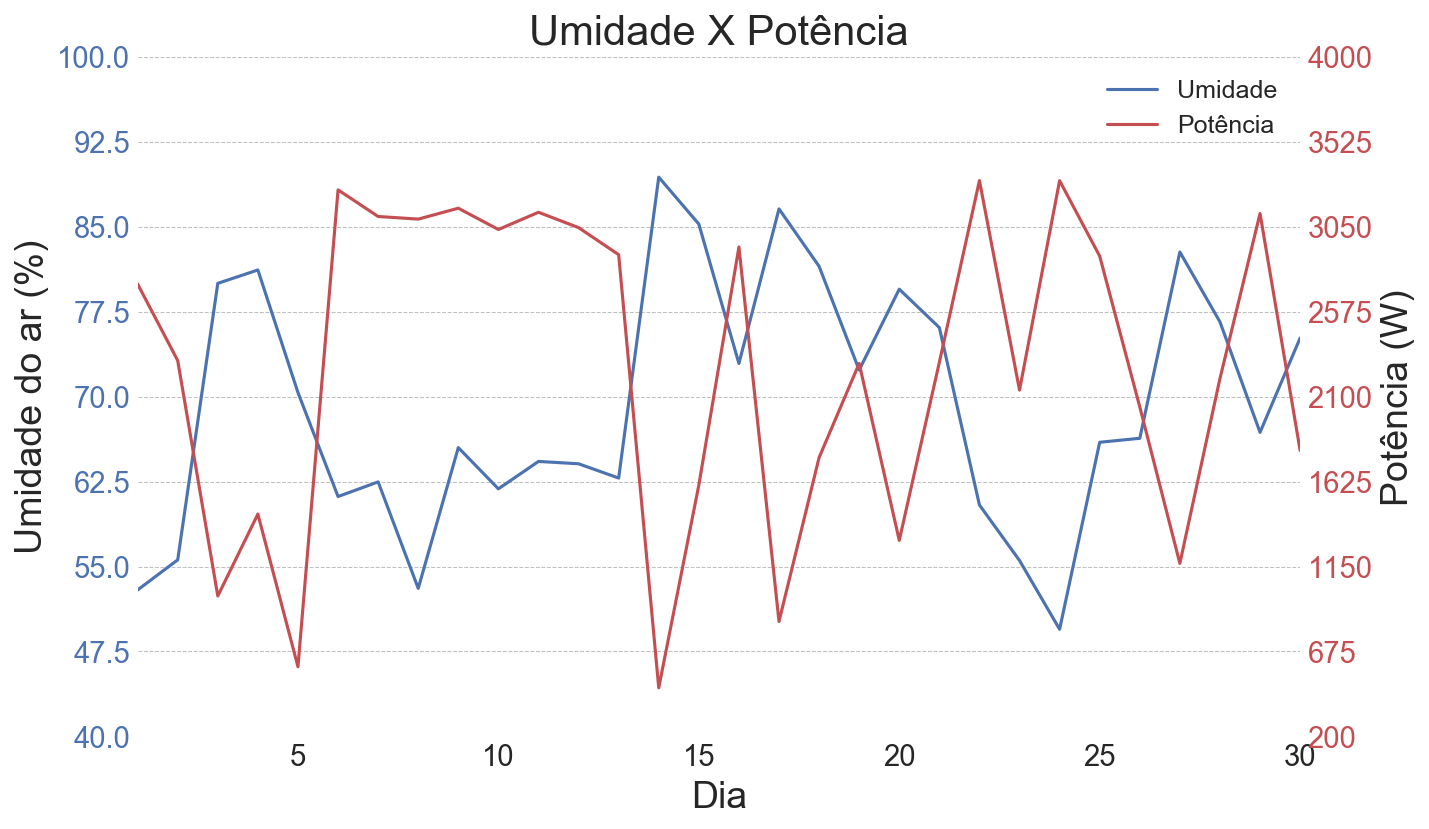

In [163]:
sns.set_style("white")  
sns.set_color_codes()

x_values = umi.dia
y_values_1 = umi.umidade_ar_vmedio

fig, ax1 = plt.subplots(figsize=(10,6))  
title = ('Umidade X Potência')

plt.title(title, fontsize=20)
plt.grid(axis='y',color='grey', linestyle='--', lw=0.5, alpha=0.5)
plt.tick_params(axis='both', labelsize=14)

plot1 = ax1.plot(x_values, y_values_1, 'b', label='Umidade')
ax1.set_ylabel('Umidade do ar (%)', fontsize=18)
ax1.set_xlabel('Dia', fontsize=18)
ax1.set_ylim(40, 100)
for tl in ax1.get_yticklabels():
    tl.set_color('b')

ax2 = ax1.twinx()
y_values_2 = pot.potencia
plot2 = ax2.plot(x_values, y_values_2, 'r', 
                 label='Potência')

ax2.set_ylabel('Potência (W)', fontsize=18)
ax2.set_ylim(200, 4000)
ax2.tick_params(axis='y', labelsize=14)
for tl in ax2.get_yticklabels():
    tl.set_color('r')

ax2.set_xlim(1, 30)
lines = plot1 + plot2

ax1.legend(lines, [l.get_label() for l in lines])
ax1.set_yticks(np.linspace(ax1.get_ybound()[0], ax1.get_ybound()[1], 9))
ax2.set_yticks(np.linspace(ax2.get_ybound()[0], ax2.get_ybound()[1], 9))

for ax in [ax1, ax2]:
    ax.spines["top"].set_visible(False)  
    ax.spines["bottom"].set_visible(False)  
    ax.spines["right"].set_visible(False)  
    ax.spines["left"].set_visible(False)  
 
plt.show()

5 - Qual a temperatura ideal para alcançar a potência máxima do painel

TypeError: 'DataFrame' object is not callable